# jHealth: train the model that scores a repetition

**Goes in:** `reps.npz`. Every repetition from the REHAB24-6 dataset, already turned into 33 body points per frame by MediaPipe (`extract_poses.py`) and cut to 64 frames (`build_dataset.py`). A physiotherapist marked each repetition as done correctly or with a mistake.

**Comes out:** one model per exercise that looks at a repetition and says how likely it contains a mistake, plus a test score measured on people the model never saw.

**How to run:** in Google Colab choose *Runtime → Run all* and upload `reps.npz` when the button appears. On your laptop, open this file in VS Code and choose `~/jhealth-cache/venv/bin/python` as the kernel. The whole notebook takes a few minutes; no GPU needed.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA = Path("data/reps.npz") if Path("data/reps.npz").exists() else Path("reps.npz")
if not DATA.exists():                      # on Colab: shows an upload button
    from google.colab import files
    files.upload()
d = np.load(DATA)

lm = d["lm"].astype(np.float32)            # (samples, 64 frames, 33 body points, xyz in metres)
exercise, person, cam, view = d["exercise"], d["person"], d["cam"], d["view"]
mistake = 1 - d["correct"]                 # 1 = the physiotherapist saw a mistake. This is what we predict.
duration = d["duration"]

NAMES = {1: "arm abduction", 2: "arm VW", 3: "push-ups", 4: "leg abduction", 5: "lunge", 6: "squat"}
EXERCISES = [e for e in (6, 5, 4, 1, 2) if len(set(person[exercise == e])) >= 3]   # need a few people to test honestly
print("lm:", lm.shape)

lm: (1927, 64, 33, 3)


## 1. What is in the data

One **sample** is one repetition seen by one camera. Each repetition was filmed by two cameras standing at a right angle to each other, so it appears twice, from two different angles.

In [2]:
rows = []
for e in EXERCISES:
    m = exercise == e
    rows.append({"exercise": NAMES[e], "samples": m.sum(), "correct": (mistake[m] == 0).sum(),
                 "with a mistake": mistake[m].sum(), "people": len(set(person[m])),
                 "average length (s)": round(float(duration[m].mean()), 1)})
pd.DataFrame(rows).set_index("exercise")

,samples,correct,with a mistake,people,average length (s)
exercise,,,,,
squat,390,268,122,9,3.3
lunge,345,155,190,8,3.4
leg abduction,420,240,180,9,2.9
arm abduction,356,180,176,9,5.1
arm VW,416,188,228,9,5.4


## 2. From body points to angles

A raw coordinate like "left knee is at x = 0.12 m" changes when the person steps sideways or is taller. An **angle** does not: a 90° knee is a 90° knee for everyone, anywhere in the picture. So we never show the model raw points. We turn each frame into a handful of measurements such as *knee angle*, *how far the trunk leans*, *how wide the knees are compared with the hips*: 17 of them for a leg exercise, 12 for an arm exercise.

One detail: some exercises use one side (arm abduction, leg abduction, lunge). For those we first work out which side is working and, if it is the left, mirror the skeleton. After that the working side is always called "right", so the model does not have to learn everything twice.

In the product this is easier: the physiotherapist's prescription already says which side to train.

In [3]:
# MediaPipe numbers its 33 body points. These are the ones we use.
L_SHOULDER, R_SHOULDER, L_ELBOW, R_ELBOW, L_WRIST, R_WRIST = 11, 12, 13, 14, 15, 16
L_HIP, R_HIP, L_KNEE, R_KNEE, L_ANKLE, R_ANKLE = 23, 24, 25, 26, 27, 28
LEFT = dict(sh=L_SHOULDER, el=L_ELBOW, wr=L_WRIST, hip=L_HIP, knee=L_KNEE, ankle=L_ANKLE)
RIGHT = dict(sh=R_SHOULDER, el=R_ELBOW, wr=R_WRIST, hip=R_HIP, knee=R_KNEE, ankle=R_ANKLE)
DOWN = np.array([0.0, 1.0, 0.0], dtype=np.float32)      # in MediaPipe's world, y points at the floor

# Index list that swaps every left point with its right twin (used for mirroring).
SWAP = np.arange(33)
for a, b in [(1, 4), (2, 5), (3, 6), (7, 8), (9, 10)] + [(i, i + 1) for i in range(11, 33, 2)]:
    SWAP[a], SWAP[b] = b, a

def length(v):
    return np.linalg.norm(v, axis=-1)

def unit(v):
    return v / (length(v)[..., None] + 1e-9)

def angle_between(u, v):
    "Angle between two directions, in degrees."
    return np.degrees(np.arccos(np.clip((unit(u) * unit(v)).sum(-1), -1, 1)))

def joint_angle(p, a, b, c):
    "Angle at point b, between the lines b->a and b->c. A straight limb gives 180."
    return angle_between(p[..., a, :] - p[..., b, :], p[..., c, :] - p[..., b, :])

def side_signals(p, s, forward):
    "Measurements for one side of the body. p has shape (..., 33, 3)."
    thigh = p[..., s["knee"], :] - p[..., s["hip"], :]
    shin = p[..., s["knee"], :] - p[..., s["ankle"], :]
    upper_arm = p[..., s["el"], :] - p[..., s["sh"], :]
    arm_len = length(upper_arm) + length(p[..., s["wr"], :] - p[..., s["el"], :])
    return {
        "knee":       joint_angle(p, s["hip"], s["knee"], s["ankle"]),   # 180 = straight leg
        "hip":        joint_angle(p, s["sh"], s["hip"], s["knee"]),      # 180 = standing tall
        "thigh_incl": angle_between(thigh, DOWN),                        # 0 = thigh points straight down
        "thigh_fwd":  (unit(thigh) * forward).sum(-1),                   # above 0 = thigh swings forward
        "knee_fwd":   (shin * forward).sum(-1) / (length(shin) + 1e-9),  # above 0 = knee in front of the ankle
        "shoulder":   joint_angle(p, s["hip"], s["sh"], s["el"]),        # 0 = arm by the side, 180 = overhead
        "elbow":      joint_angle(p, s["sh"], s["el"], s["wr"]),         # 180 = straight arm
        "wrist_h":    (p[..., s["sh"], 1] - p[..., s["wr"], 1]) / (arm_len + 1e-9),   # above 0 = wrist over the shoulder
        "arm_fwd":    (unit(upper_arm) * forward).sum(-1),               # above 0 = arm goes forward, not sideways
    }

def body_signals(p):
    "Measurements that use both sides at once."
    mid_sh = (p[..., L_SHOULDER, :] + p[..., R_SHOULDER, :]) / 2
    mid_hip = (p[..., L_HIP, :] + p[..., R_HIP, :]) / 2
    mid_ankle = (p[..., L_ANKLE, :] + p[..., R_ANKLE, :]) / 2
    sh_line = p[..., R_SHOULDER, :] - p[..., L_SHOULDER, :]
    hip_line = p[..., R_HIP, :] - p[..., L_HIP, :]
    leg_len = sum(length(p[..., s["knee"], :] - p[..., s["hip"], :]) + length(p[..., s["knee"], :] - p[..., s["ankle"], :])
                  for s in (LEFT, RIGHT)) / 2
    return {
        "trunk_lean":    angle_between(mid_sh - mid_hip, -DOWN),                     # 0 = upright
        "shoulder_tilt": np.degrees(np.arcsin(np.clip(unit(sh_line)[..., 1], -1, 1))),   # 0 = shoulders level
        "pelvis_tilt":   np.degrees(np.arcsin(np.clip(unit(hip_line)[..., 1], -1, 1))),  # 0 = hips level
        "knee_gap":      length(p[..., R_KNEE, :] - p[..., L_KNEE, :]) / (length(hip_line) + 1e-9),   # under 1 = knees closer than hips
        "ankle_gap":     length(p[..., R_ANKLE, :] - p[..., L_ANKLE, :]) / (length(hip_line) + 1e-9), # stance width
        "hip_h":         (mid_ankle[..., 1] - mid_hip[..., 1]) / (leg_len + 1e-9),   # about 1 = standing, smaller = lower
        "wrist_gap":     length(p[..., R_WRIST, :] - p[..., L_WRIST, :]) / (length(sh_line) + 1e-9),
        "thigh_spread":  angle_between(p[..., L_KNEE, :] - p[..., L_HIP, :], p[..., R_KNEE, :] - p[..., R_HIP, :]),
    }

def forward_axis(p):
    "Unit vector, level with the floor, pointing where the chest points."
    right = unit(p[..., R_SHOULDER, :] - p[..., L_SHOULDER, :])     # from the left shoulder to the right one
    return unit(np.cross(-DOWN, right))

# For one-sided exercises: how we tell which side is working.
#   arm / leg abduction: the side whose arm / thigh swings through the bigger range
#   lunge: the front leg is the one whose thigh points forward
WORKING_SIDE_BY = {1: ("shoulder", "range"), 4: ("thigh_incl", "range"), 5: ("thigh_fwd", "mean")}
# A leg exercise is judged on legs and trunk, an arm exercise on arms and trunk.
AREA = {6: "legs", 5: "legs", 4: "legs", 1: "arms", 2: "arms"}
PAIRED = {"legs": ["knee", "hip", "thigh_incl", "thigh_fwd", "knee_fwd"],
          "arms": ["shoulder", "elbow", "wrist_h", "arm_fwd"]}
SINGLE = {"legs": ["trunk_lean", "shoulder_tilt", "pelvis_tilt", "knee_gap", "ankle_gap", "hip_h", "thigh_spread"],
          "arms": ["trunk_lean", "shoulder_tilt", "pelvis_tilt", "wrist_gap"]}

def left_is_working(p, ex):
    "True for reps where the left side moves more than the right. p: (reps, frames, 33, 3)."
    f = forward_axis(p)
    key, how = WORKING_SIDE_BY[ex]
    l, r = side_signals(p, LEFT, f)[key], side_signals(p, RIGHT, f)[key]
    return np.ptp(l, axis=1) > np.ptp(r, axis=1) if how == "range" else l.mean(axis=1) > r.mean(axis=1)

def mirror(p):
    "Swap left and right, as if looking at the person in a mirror."
    q = p[..., SWAP, :].copy()
    q[..., 0] *= -1
    return q

def signals(p, ex):
    "(reps, frames, 33, 3) -> names, array (reps, signals, frames)"
    p = p.copy()
    one_sided = ex in WORKING_SIDE_BY
    if one_sided:
        flip = left_is_working(p, ex)
        p[flip] = mirror(p[flip])
    f = forward_axis(p)
    left, right, body = side_signals(p, LEFT, f), side_signals(p, RIGHT, f), body_signals(p)
    names, series = [], []
    for k in PAIRED[AREA[ex]]:
        if one_sided:   # working side and resting side
            names += [f"work_{k}", f"rest_{k}"]; series += [right[k], left[k]]
        else:           # both sides do the same: keep the average and the left-right difference
            names += [f"avg_{k}", f"diff_{k}"]; series += [(left[k] + right[k]) / 2, np.abs(left[k] - right[k])]
    for k in SINGLE[AREA[ex]]:
        names.append(k)
        series.append(body[k] if one_sided or "tilt" not in k else np.abs(body[k]))
    return names, np.stack(series, axis=1).astype(np.float32)

SIG = {}
for e in EXERCISES:
    SIGNAL_NAMES, SIG[e] = signals(lm[exercise == e], e)
    print(f"{NAMES[e]:14s} signals {SIG[e].shape}")

squat          signals (390, 17, 64)
lunge          signals (345, 17, 64)


leg abduction  signals (420, 17, 64)
arm abduction  signals (356, 12, 64)


arm VW         signals (416, 12, 64)


**Sanity check.** The dataset says which leg worked in leg abduction and which leg was in front in the lunge. Our "which side is working" rule never saw those labels, so comparing the two tells us whether the rule can be trusted: about 98% for the lunge and 93% for leg abduction.

The arm abduction line is not a real accuracy. In this dataset that exercise is *always* the right arm, so the "agreement" only measures how often our rule wrongly picks the left arm (about 14%). We tried forcing the right arm and the score did not change, so the rule was left as it is.

In [4]:
subtype = d["subtype"]
for e in [e for e in EXERCISES if e in WORKING_SIDE_BY]:
    m = exercise == e
    ours = left_is_working(lm[m], e)
    theirs = np.char.find(subtype[m], "left") >= 0
    print(f"{NAMES[e]:14s} our rule agrees with the dataset's side label on {100 * (ours == theirs).mean():.0f}% of samples")

lunge          our rule agrees with the dataset's side label on 98% of samples
leg abduction  our rule agrees with the dataset's side label on 93% of samples
arm abduction  our rule agrees with the dataset's side label on 86% of samples


Here is what the model will look at. Each line is one squat by one person, start to finish. Green = the physiotherapist said correct, red = mistake.

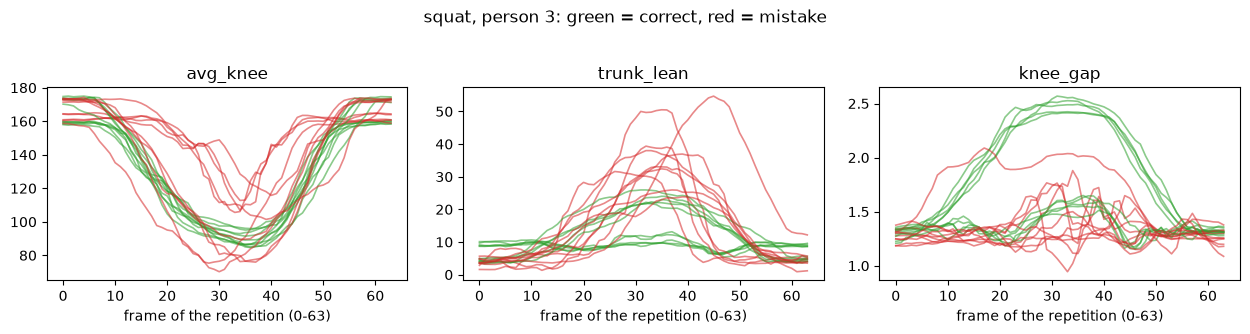

In [5]:
def plot_reps(ex, who, keys):
    m = (exercise == ex)
    sel = (person[m] == who) & (cam[m] == 17)
    fig, axes = plt.subplots(1, len(keys), figsize=(4.2 * len(keys), 3.2))
    for ax, k in zip(np.atleast_1d(axes), keys):
        i = [n for n in signals(lm[m][:1], ex)[0]].index(k)
        for curve, bad in zip(SIG[ex][sel][:, i], mistake[m][sel]):
            ax.plot(curve, color="tab:red" if bad else "tab:green", alpha=0.55, lw=1.2)
        ax.set_title(k); ax.set_xlabel("frame of the repetition (0-63)")
    fig.suptitle(f"{NAMES[ex]}, person {who}: green = correct, red = mistake", y=1.03)
    plt.tight_layout(); plt.show()

if 6 in EXERCISES:
    who = max(set(person[exercise == 6]), key=lambda p: min((mistake[(exercise == 6) & (person == p)] == v).sum() for v in (0, 1)))
    plot_reps(6, who, ["avg_knee", "trunk_lean", "knee_gap"])

**How much can we trust one camera?** Every repetition was filmed by two cameras at once. If the measurements were perfect, both cameras would report the same angle for the same repetition. They do not: depth is a guess when you only have one flat picture. The gap between the two cameras is our measuring error, and no model can be more precise than its ruler.

In [6]:
video, rep_no = d["video"], d["rep"]
CHECK = {6: ("avg_knee", np.min, "deepest knee angle"), 5: ("work_knee", np.min, "deepest front-knee angle"),
         4: ("work_thigh_incl", np.max, "highest leg lift"), 1: ("work_shoulder", np.max, "highest arm lift"),
         2: ("avg_shoulder", np.max, "highest arm lift")}
for e in EXERCISES:
    m = exercise == e
    key, pick, label = CHECK[e]
    value = pick(SIG[e][:, signals(lm[m][:1], e)[0].index(key)], axis=1)
    seen = {(v, r, c): x for v, r, c, x in zip(video[m], rep_no[m], cam[m], value)}
    both = np.array([(seen[v, r, 17], seen[v, r, 18]) for (v, r, c) in seen if c == 17 and (v, r, 18) in seen])
    if len(both) < 10:
        continue
    print(f"{NAMES[e]:14s} {label:25s} the two cameras differ by {np.abs(both[:, 0] - both[:, 1]).mean():4.1f} degrees on average "
          f"(correlation {np.corrcoef(both.T)[0, 1]:.2f}, {len(both)} reps)")

squat          deepest knee angle        the two cameras differ by 12.5 degrees on average (correlation 0.73, 195 reps)
lunge          deepest front-knee angle  the two cameras differ by 12.7 degrees on average (correlation 0.60, 172 reps)
leg abduction  highest leg lift          the two cameras differ by 21.1 degrees on average (correlation 0.48, 210 reps)
arm abduction  highest arm lift          the two cameras differ by 38.0 degrees on average (correlation 0.51, 178 reps)
arm VW         highest arm lift          the two cameras differ by  7.7 degrees on average (correlation 0.38, 208 reps)


## 3. One row of numbers per repetition

A curve of 64 points is awkward for a simple model. So we summarise every curve with 11 numbers:

- **how big it is:** lowest value, highest value, range (highest minus lowest), average, and how much it wiggles (standard deviation);
- **when it happens:** at what point of the rep the lowest and the highest value occur (0 = start, 1 = end);
- **how it moves:** average speed, fastest speed, jerkiness (how abruptly the speed changes), and first half versus second half (going down versus coming back up).

The last two groups are about *tempo and control*, which is what a physiotherapist often means by a mistake: dropping too fast, a wobble at the bottom, a slow struggle on the way up. We tested adding them: the score rose by about 0.02 on average, which is small but consistent with that idea.

For a squat that is 17 curves × 11 numbers + the rep's duration = **188 numbers per repetition** (133 for an arm exercise). That table is what the simple models learn from.

In [7]:
STATS = ["min", "max", "range", "mean", "std", "when_min", "when_max", "speed", "peak_speed", "jerk", "first_vs_second_half"]

def summarise(sig, dur):
    "(reps, signals, frames) -> (reps, signals * 11 + 1)"
    n = sig.shape[-1]
    speed = np.abs(np.diff(sig, axis=-1)) * n                          # change per whole repetition
    parts = [sig.min(-1), sig.max(-1), np.ptp(sig, -1), sig.mean(-1), sig.std(-1),
             sig.argmin(-1) / n, sig.argmax(-1) / n,                   # when the lowest / highest value happens
             speed.mean(-1), speed.max(-1),                            # average and fastest movement
             np.abs(np.diff(sig, n=2, axis=-1)).mean(-1),              # jerkiness
             sig[..., :n // 2].mean(-1) - sig[..., n // 2:].mean(-1)]  # going down versus coming back up
    return np.concatenate([np.stack(parts, -1).reshape(len(sig), -1), dur[:, None]], axis=1)

X, Y, WHO, VIEW, FEATURES = {}, {}, {}, {}, {}
for e in EXERCISES:
    m = exercise == e
    names = signals(lm[m][:1], e)[0]
    X[e], Y[e], WHO[e], VIEW[e] = summarise(SIG[e], duration[m]), mistake[m], person[m], view[m]
    FEATURES[e] = [f"{n}:{s}" for n in names for s in STATS] + ["duration"]
print({NAMES[e]: X[e].shape for e in EXERCISES})

{'squat': (390, 188), 'lunge': (345, 188), 'leg abduction': (420, 188), 'arm abduction': (356, 133), 'arm VW': (416, 133)}


## 4. How to test honestly

If the same person appears in training and in the test, the model can cheat: it recognises *the person* (their height, their habits) instead of *the mistake*. The score looks great and means nothing, because a real patient is always someone new.

So we test like this: hide one person completely, train on everyone else, predict the hidden person. Repeat until every person has been the hidden one. This is called **leave-one-person-out**. Every prediction in this notebook is made on a person the model has never seen.

The scores:
- **accuracy**: share of reps judged right. Easy to fool: if 70% of reps are correct, a model that always says "correct" gets 70%.
- **F1 (mistake)**: how well the model catches mistakes, punishing both missed mistakes and false alarms. 1.0 is perfect.
- **macro F1**: the average of F1 for "mistake" and F1 for "correct". This is the single number for the slide.
- **AUC**: if we pick one bad rep and one good rep at random, how often the model gives the bad one the higher mistake score. 0.5 is a coin flip.

In [8]:
def leave_one_person_out(make_model, X, y, who):
    "Returns, for every sample, the mistake probability from a model that never saw that person."
    prob = np.zeros(len(y))
    for p in np.unique(who):
        hidden = who == p
        model = make_model().fit(X[~hidden], y[~hidden])
        prob[hidden] = model.predict_proba(X[hidden])[:, 1]
    return prob

def scores(y, prob):
    pred = (prob >= 0.5).astype(int)
    return {"accuracy": accuracy_score(y, pred), "F1 (mistake)": f1_score(y, pred, zero_division=0),
            "macro F1": f1_score(y, pred, average="macro", zero_division=0),
            "AUC": roc_auc_score(y, prob) if prob.std() > 0 else 0.5}

## 5. Three simple models

1. **Always say "correct".** Not a model, just the floor. Anything useful must beat it.
2. **Logistic regression.** Gives each number a weight and adds them up. Fast, simple, a classic baseline.
3. **Random forest.** 300 decision trees. Each tree asks yes/no questions ("is the lowest knee angle under 95°?") and votes; the forest averages the votes. It copes well with few examples and mixed kinds of numbers, and it can tell us which measurements mattered.

In [9]:
def always_correct():
    class M:
        def fit(self, X, y): return self
        def predict_proba(self, X): return np.tile([1.0, 0.0], (len(X), 1))
    return M()

def logistic():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000, class_weight="balanced"))

def forest():
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced", n_jobs=-1, random_state=0)

MODELS = {"always 'correct'": always_correct, "logistic regression": logistic, "random forest": forest}
PROB = {name: {e: leave_one_person_out(make, X[e], Y[e], WHO[e]) for e in EXERCISES} for name, make in MODELS.items()}
print("done")

done


## 6. A small neural network on the full curves

The two simple models only see five summary numbers per curve. A **1D-CNN** reads the whole 64-frame curves, so it can notice *when* something happens (for example a knee that caves in only on the way up). It slides small windows along time, like an image network slides windows across a picture.

With only a few hundred examples per exercise a neural network often loses to a forest. We train it anyway and let the test decide.

In [10]:
class RepCNN(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(channels, 32, 5, padding=2), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 64, 3, padding=1), nn.BatchNorm1d(64), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(64, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)

class CNNModel:
    "Wraps the network so it has the same fit / predict_proba buttons as the other models."
    def __init__(self, epochs=40, seed=0):
        self.epochs, self.seed = epochs, seed

    def fit(self, S, y):
        torch.manual_seed(self.seed)
        self.mean = S.mean((0, 2), keepdims=True); self.std = S.std((0, 2), keepdims=True) + 1e-6
        x = torch.tensor((S - self.mean) / self.std); t = torch.tensor(y, dtype=torch.float32)
        self.net = RepCNN(S.shape[1])
        opt = torch.optim.AdamW(self.net.parameters(), lr=1e-3, weight_decay=1e-2)
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=(1 - t.mean()) / t.mean())   # mistakes are rarer: weigh them up
        for _ in range(self.epochs):
            self.net.train()
            for idx in torch.randperm(len(x)).split(32):
                if len(idx) < 2:
                    continue
                xb = x[idx] + 0.05 * torch.randn_like(x[idx])      # a little noise so it cannot memorise
                opt.zero_grad(); loss_fn(self.net(xb), t[idx]).backward(); opt.step()
        return self

    def predict_proba(self, S):
        self.net.eval()
        with torch.no_grad():
            p = torch.sigmoid(self.net(torch.tensor((S - self.mean) / self.std))).numpy()
        return np.stack([1 - p, p], axis=1)

PROB["1D-CNN"] = {e: leave_one_person_out(CNNModel, SIG[e], Y[e], WHO[e]) for e in EXERCISES}
print("parameters in the network:", sum(p.numel() for p in RepCNN(SIG[EXERCISES[0]].shape[1]).parameters()))

parameters in the network: 25793


## 7. Results

Every number below is measured on people the model never saw during training.

macro F1 on unseen people (higher is better, 1.0 is perfect)


model,always 'correct',logistic regression,random forest,1D-CNN
exercise,,,,
squat,0.41,0.72,0.66,0.71
lunge,0.31,0.65,0.59,0.68
leg abduction,0.36,0.76,0.75,0.72
arm abduction,0.34,0.63,0.70,0.63
arm VW,0.31,0.69,0.69,0.66
ALL,0.35,0.70,0.70,0.69


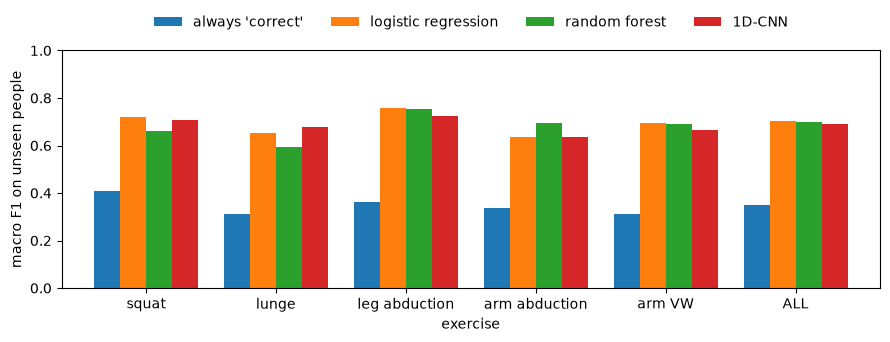

,accuracy,F1 (mistake),macro F1,AUC
exercise,,,,
squat,0.71,0.54,0.66,0.77
lunge,0.62,0.69,0.59,0.66
leg abduction,0.76,0.70,0.75,0.84
arm abduction,0.70,0.70,0.70,0.76
arm VW,0.69,0.72,0.69,0.75
ALL,0.70,0.68,0.70,0.77


In [11]:
rows = []
for name in PROB:
    for e in EXERCISES:
        rows.append({"model": name, "exercise": NAMES[e], **scores(Y[e], PROB[name][e])})
    y_all = np.concatenate([Y[e] for e in EXERCISES]); p_all = np.concatenate([PROB[name][e] for e in EXERCISES])
    rows.append({"model": name, "exercise": "ALL", **scores(y_all, p_all)})
RESULTS = pd.DataFrame(rows)
order = list(PROB)
table = RESULTS.pivot(index="exercise", columns="model", values="macro F1")[order].loc[[NAMES[e] for e in EXERCISES] + ["ALL"]]
print("macro F1 on unseen people (higher is better, 1.0 is perfect)")
display(table.round(2))

ax = table.plot.bar(figsize=(9, 3.6), width=0.8, rot=0)
ax.set_ylabel("macro F1 on unseen people"); ax.set_ylim(0, 1); ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.2), frameon=False)
plt.tight_layout(); plt.show()

display(RESULTS[RESULTS.model == "random forest"].set_index("exercise").drop(columns="model").round(2))

**Why the honest test matters.** Below is the same forest, tested the usual lazy way: shuffle all repetitions and split them at random, so the same people are in training and in the test. Compare it with the honest number. The gap is how much a model can gain just by recognising people. If you ever see a rehab-AI demo quoting 95%, ask which of these two tests it was.

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
rows = []
for e in EXERCISES:
    lazy = cross_val_predict(forest(), X[e], Y[e], cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
    rows.append({"exercise": NAMES[e], "lazy: random split": scores(Y[e], lazy)["macro F1"],
                 "honest: unseen people": scores(Y[e], PROB["random forest"][e])["macro F1"]})
print("random forest, macro F1 (lazy = the same people are in training and in the test)")
display(pd.DataFrame(rows).set_index("exercise").round(2))

random forest, macro F1 (lazy = the same people are in training and in the test)


,lazy: random split,honest: unseen people
exercise,,
squat,0.89,0.66
lunge,0.86,0.59
leg abduction,0.83,0.75
arm abduction,0.90,0.70
arm VW,0.84,0.69


Three more honest looks at the forest: how it does on each hidden person (some people are much harder than others), how it does from each camera angle, and the raw counts of right and wrong answers.

In [13]:
per_person = pd.DataFrame({NAMES[e]: pd.Series({f"person {p}": accuracy_score(Y[e][WHO[e] == p], PROB["random forest"][e][WHO[e] == p] >= 0.5)
                                                for p in np.unique(WHO[e])}) for e in EXERCISES})
print("random forest: accuracy on each hidden person")
display(per_person.round(2))

by_view = pd.DataFrame({NAMES[e]: pd.Series({v: f1_score(Y[e][VIEW[e] == v], PROB["random forest"][e][VIEW[e] == v] >= 0.5, average="macro")
                                             for v in ("front", "half-profile", "profile") if (VIEW[e] == v).sum() >= 20}) for e in EXERCISES})
print("random forest: macro F1 by camera angle (front = person faces the camera)")
display(by_view.round(2))

for e in EXERCISES:
    tn, fp, fn, tp = confusion_matrix(Y[e], (PROB["random forest"][e] >= 0.5).astype(int)).ravel()
    print(f"{NAMES[e]:14s} correct reps: {tn} passed, {fp} false alarms   |   reps with a mistake: {tp} caught, {fn} missed")

random forest: accuracy on each hidden person


,squat,lunge,leg abduction,arm abduction,arm VW
person 1,0.89,NaN,0.73,0.50,0.92
person 2,0.70,0.62,0.76,0.78,0.58
person 3,0.72,0.43,0.67,0.90,0.95
person 4,0.80,0.57,0.81,0.50,0.72
person 5,0.62,0.48,0.79,0.69,0.70
person 6,0.74,0.80,0.90,1.00,0.33
person 7,0.70,0.82,0.82,0.75,0.65
person 8,0.36,0.48,0.74,0.70,0.70
person 9,0.76,0.78,0.67,0.66,0.66


random forest: macro F1 by camera angle (front = person faces the camera)


,squat,lunge,leg abduction,arm abduction,arm VW
front,0.58,0.66,0.82,0.78,0.64
half-profile,0.66,0.62,0.77,0.72,0.73
profile,0.70,0.46,0.65,0.57,0.66


squat          correct reps: 207 passed, 61 false alarms   |   reps with a mistake: 68 caught, 54 missed
lunge          correct reps: 64 passed, 91 false alarms   |   reps with a mistake: 149 caught, 41 missed
leg abduction  correct reps: 202 passed, 38 false alarms   |   reps with a mistake: 118 caught, 62 missed
arm abduction  correct reps: 123 passed, 57 false alarms   |   reps with a mistake: 125 caught, 51 missed
arm VW         correct reps: 127 passed, 61 false alarms   |   reps with a mistake: 162 caught, 66 missed


## 8. Which measurements matter

A forest can report how much each number helped its trees separate good reps from bad ones. This is useful twice: it tells us whether the model looks at sensible things, and it gives the coach something to say ("your trunk leaned further than usual").

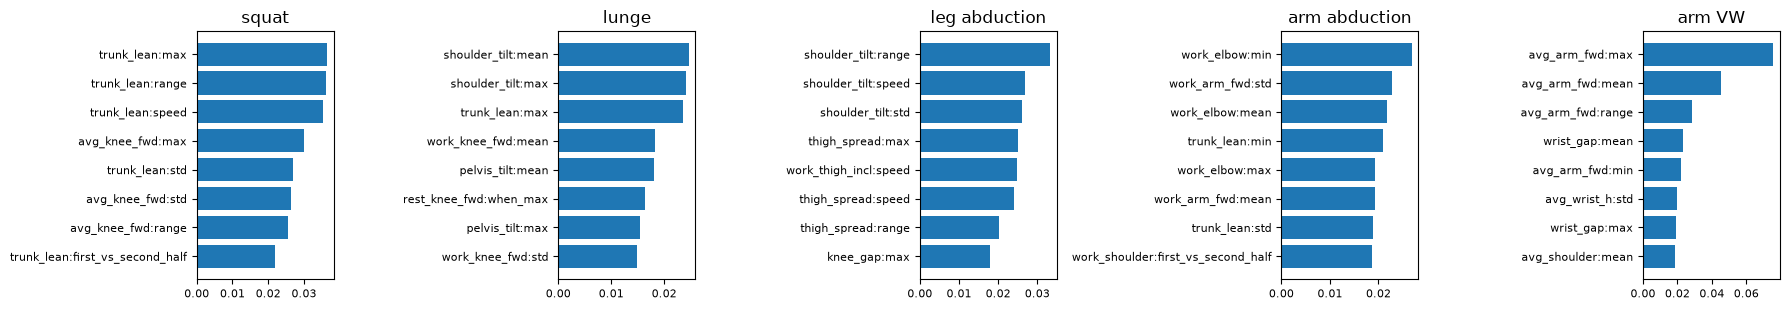

In [14]:
FINAL = {e: forest().fit(X[e], Y[e]) for e in EXERCISES}     # forests trained on everyone, to read off what they use
fig, axes = plt.subplots(1, len(EXERCISES), figsize=(3.6 * len(EXERCISES), 3.2))
for ax, e in zip(np.atleast_1d(axes), EXERCISES):
    imp = pd.Series(FINAL[e].feature_importances_, index=FEATURES[e]).nlargest(8)[::-1]
    ax.barh(imp.index, imp.values, color="tab:blue"); ax.set_title(NAMES[e]); ax.tick_params(labelsize=8)
plt.tight_layout(); plt.show()

## 9. Export for the app

The app runs in the browser, in JavaScript, so the model has to be carried over. Both simple models are easy to carry: logistic regression is one list of weights, a forest is a list of yes/no questions. We export whichever of the two scored better overall, as JSON. The cell then re-reads the JSON with a few lines of plain code and checks that it gives the same answers as scikit-learn, so we know a JavaScript version can match exactly.

`quality score shown to the patient = 100 × (1 − mistake probability)`

In [15]:
OUT = Path("models"); OUT.mkdir(exist_ok=True)
overall = RESULTS[RESULTS.exercise == "ALL"].set_index("model")["macro F1"][["logistic regression", "random forest"]]
BEST = overall.idxmax()
print(f"exporting: {BEST}  (macro F1 on unseen people, all exercises together: {overall[BEST]:.2f})")

def model_to_dict(model):
    if isinstance(model, RandomForestClassifier):
        trees = []
        for est in model.estimators_:
            t = est.tree_; v = t.value[:, 0, :]
            trees.append({"feature": t.feature.tolist(), "threshold": t.threshold.tolist(), "left": t.children_left.tolist(),
                          "right": t.children_right.tolist(), "p_mistake": (v[:, 1] / v.sum(1)).tolist()})
        return {"type": "forest", "trees": trees}
    scaler, lr = model[0], model[1]
    return {"type": "logistic", "mean": scaler.mean_.tolist(), "scale": scaler.scale_.tolist(),
            "weights": lr.coef_[0].tolist(), "bias": float(lr.intercept_[0])}

def predict_from_dict(m, x):
    "The whole model without scikit-learn. This is the part that gets rewritten in JavaScript."
    if m["type"] == "logistic":
        z = m["bias"] + sum(w * (v - mu) / sd for w, v, mu, sd in zip(m["weights"], x, m["mean"], m["scale"]))
        return 1 / (1 + np.exp(-z))
    total = 0.0
    for t in m["trees"]:
        node = 0
        while t["left"][node] != -1:
            node = t["left"][node] if x[t["feature"][node]] <= t["threshold"][node] else t["right"][node]
        total += t["p_mistake"][node]
    return total / len(m["trees"])

EXPORTED = {}
for e in EXERCISES:
    EXPORTED[e] = MODELS[BEST]().fit(X[e], Y[e])                 # final model: trained on everyone
    body = model_to_dict(EXPORTED[e])
    spec = {"exercise": NAMES[e], "model": BEST, "body_area": AREA[e], "one_sided": e in WORKING_SIDE_BY,
            "working_side_by": list(WORKING_SIDE_BY.get(e, [])), "frames": int(lm.shape[1]),
            "signals": signals(lm[exercise == e][:1], e)[0], "stats": STATS, "features": FEATURES[e],
            "tested_on_unseen_people": {k: round(float(v), 3) for k, v in scores(Y[e], PROB[BEST][e]).items()},
            "training": {"samples": int(len(Y[e])), "people": int(len(set(WHO[e]))), "dataset": "REHAB24-6 (CC BY-NC 4.0, research use only)"},
            **body}
    path = OUT / f"{NAMES[e].replace(' ', '_')}.json"
    path.write_text(json.dumps(spec))
    x32 = X[e].astype(np.float32)
    gap = np.abs(np.array([predict_from_dict(body, row) for row in x32[:50]]) - EXPORTED[e].predict_proba(x32[:50])[:, 1]).max()
    print(f"saved {path}  ({path.stat().st_size / 1e3:.0f} kB)   biggest difference from scikit-learn: {gap:.1e}")

# One worked example for testing the JavaScript port: body points in, features and answer out.
e = EXERCISES[0]; i = int(np.flatnonzero(exercise == e)[0])
(OUT / "parity_test.json").write_text(json.dumps({
    "exercise": NAMES[e], "landmarks": lm[i].round(5).tolist(), "duration": float(duration[i]),
    "features": X[e][0].tolist(), "p_mistake": float(EXPORTED[e].predict_proba(X[e][:1].astype(np.float32))[0, 1])}))
RESULTS.round(3).to_csv(OUT / "results.csv", index=False)
print("saved models/parity_test.json and models/results.csv")

exporting: logistic regression  (macro F1 on unseen people, all exercises together: 0.70)
saved models/squat.json  (17 kB)   biggest difference from scikit-learn: 2.2e-07
saved models/lunge.json  (17 kB)   biggest difference from scikit-learn: 2.6e-07
saved models/leg_abduction.json  (17 kB)   biggest difference from scikit-learn: 2.0e-07
saved models/arm_abduction.json  (12 kB)   biggest difference from scikit-learn: 2.0e-07
saved models/arm_VW.json  (12 kB)   biggest difference from scikit-learn: 1.9e-07
saved models/parity_test.json and models/results.csv


## What these numbers mean, and what they do not

- The score is for **healthy adults aged 25 to 50 in a lab**, filmed by two fixed cameras. It is not yet a score for older patients on a laptop webcam at home. That number comes from recording your own clips and holding one teammate out.
- "Mistake" means *whatever this physiotherapist asked that person to do wrong*. The mistakes differ from person to person, which is why some hidden people score far lower than others.
- We compared several models on the same test and kept the best, so the best number is slightly flattering. The fair way to confirm it is a fresh person the model has never been compared on: your own recordings.
- The dataset licence is **non-commercial research only**. Fine for a hackathon prototype. Say on the slide that a product would train on consented patient data.
- One camera is a rough ruler: section 2 shows two cameras disagreeing by 10 to 20 degrees on the same repetition. Show trends over weeks, never a clinical measurement.